# Défi IA 2025 : eau et nuages dans l'atmosphère d'exoplanètes

La mission ARIEL de l'ESA, prévue pour un lancement en 2029, cherche à caractériser l'atmosphère de 1000 exoplanètes.  
Elle utilise une méthode d'observation indirecte des exoplanètes en restant fixé sur la lumière de son étoile hôte et en attendant de voir la période de transit, c'est à dire le moment où la planète passe devant l'étoile.  
L'objectif de ce défi IA est d'extraire depuis des observations d'ARIEL simulées la présence ou l'absence d'eau et de nuages.

## Données d'entrée : spectre

Le transit impacte le rapport de flux au travers des longueurs d'onde observées par les instruments d'ARIEL : FGS et AIRS. La pipeline de transformation de données d'ARIEL transforme l'observation d'un transit en un spectre exploitable, c'est le produit de niveau 3.  
Dans ce Défi IA, le spectre est la principale entrée. 

Le spectre donne pour chaque longueur d'onde la profondeur de transit. Les instruments FGS (caméra visible, gamme spectrale de 1.1 à 1.95 microns) et AIRS (spectromètre infrarouge, gamme spectrale de 1.95 à 7.8 microns) sont sujets à différents bruits pendant leurs observations. Les points du spectre sont donc partiellement incertains à un degré défini dans les spécifications de la mission.  
Les spectres du défi IA proviennent d'un simulateur appelé Taurex, permettant une fidèle représentativité des instruments FGS et ARIEL.
Dans le jeu de données du défi IA, le spectre est échantilloné sur 52 points de données, avec pour chaque point l'information d'incertitude et la moyenne dans l'incertitude.

## Données d'entrée : les informations auxiliaires
En plus du spectre, des informations du système planètaire sont disponibles pour chaque opération. Elles correspondent aux paramètres de l’étoile, à la masse de la planète et au demi grand-axe.

## Imports et chargement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

In [2]:
spectra_train = np.load("../data/spectra.npy")
aux_train = pd.read_csv("../data/auxiliary.csv")
targets_train = pd.read_csv("../data/targets.csv")

spectra_test = np.load("../data/spectra_test.npy")
aux_test = pd.read_csv("../data/auxiliary_test.csv")

print("Spectres train :", spectra_train.shape, "| test :", spectra_test.shape)

Spectres train : (3000, 52, 3) | test : (1032, 52, 3)


Chaque spectre contient 52 points : longueur d'onde, profondeur de transit et incertitude.

In [3]:
aux_train.head()

,star_mass_kg,star_radius_m,star_temperature,planet_mass_kg,semi_major_axis_m
0,1.570836e+30,494402820.0,5033.0,1.262481e+26,2.277510e+10
1,1.710024e+30,591890700.0,5320.0,3.959436e+25,1.217744e+10
2,1.153272e+30,382988100.0,3985.0,8.958000e+25,1.057672e+10
3,3.777960e+29,146231820.0,2988.0,3.810136e+25,1.431672e+10
4,1.371996e+30,445658880.0,4925.0,8.360800e+25,1.795200e+10


In [4]:
targets_train.head()

,id,eau,nuage
0,0,0,1
1,1,1,0
2,2,0,0
3,3,1,1
4,4,1,1


### Affichage d'un spectre

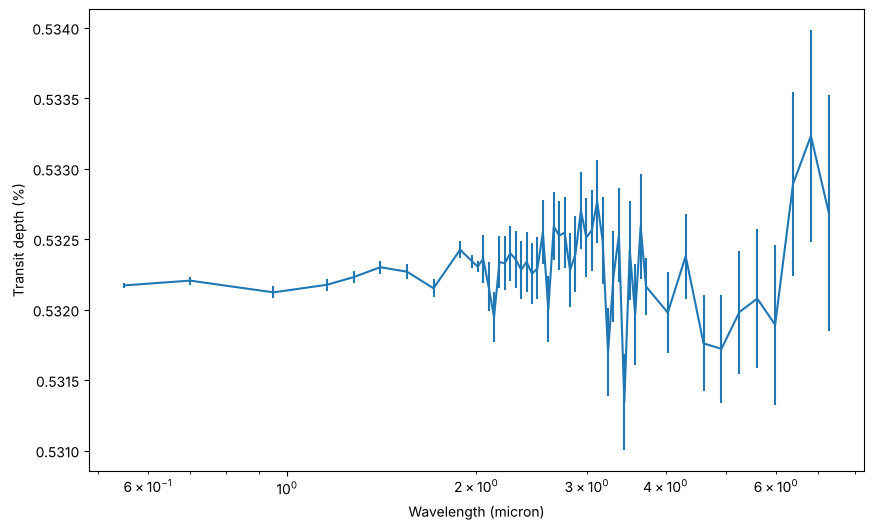

In [5]:
def visualise_spectrum(spectrum):
    ## Multipication par 100 pour passer en pourcentage 
    plt.errorbar(x=spectrum[:,0], y= spectrum[:,1]*100, yerr=spectrum[:,2]*100 )
    ## On a l'habitude de lire les spectres en échelle log
    plt.xscale('log')
    plt.xlabel('Wavelength (micron)')
    plt.ylabel('Transit depth (%)')

fig = plt.figure(figsize=(10,6))
visualise_spectrum(spectra_train[3])
plt.show()

### Affichage d'un autre spectre

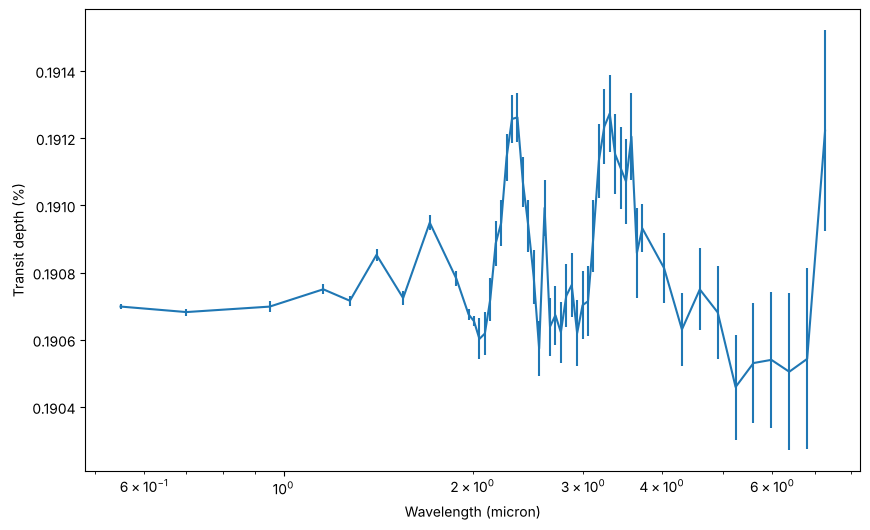

In [6]:
fig = plt.figure(figsize=(10,6))
visualise_spectrum(spectra_train[400])
plt.show()

On peut observer que la moyenne du spectre diffère sensiblement d'un spectre à un autre, c'est un effet direct de la taille du rayon. Plus une planète est large, plus son rapport de profondeur de transit sera important. On peut également voir que les barres d'incertitudes ne sont pas également réparties, avec moins d'erreur sur les bandes FGS (1.1 à 1.95 microns) comparés aux bandes d'AIRS.

### Répartition des spectres

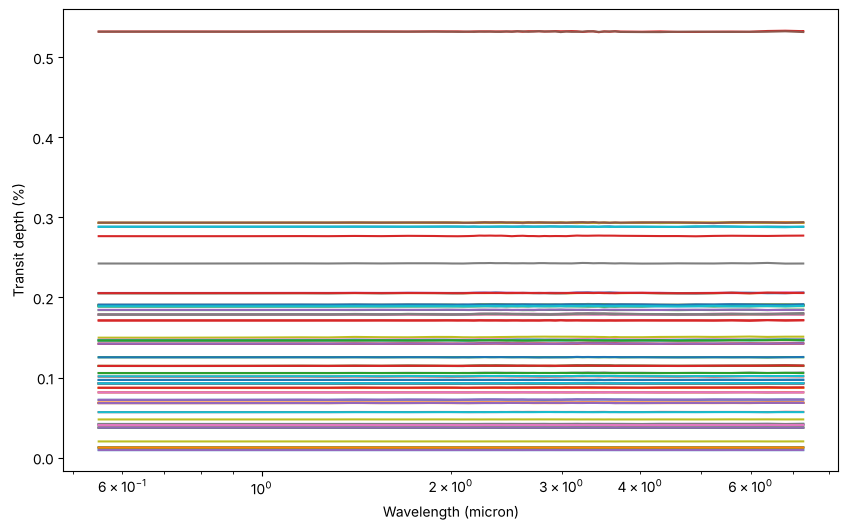

In [7]:
fig = plt.figure(figsize=(10,6))
for i in range(0, 100):
    visualise_spectrum(spectra_train[i])
plt.show()

### Répartition des labels

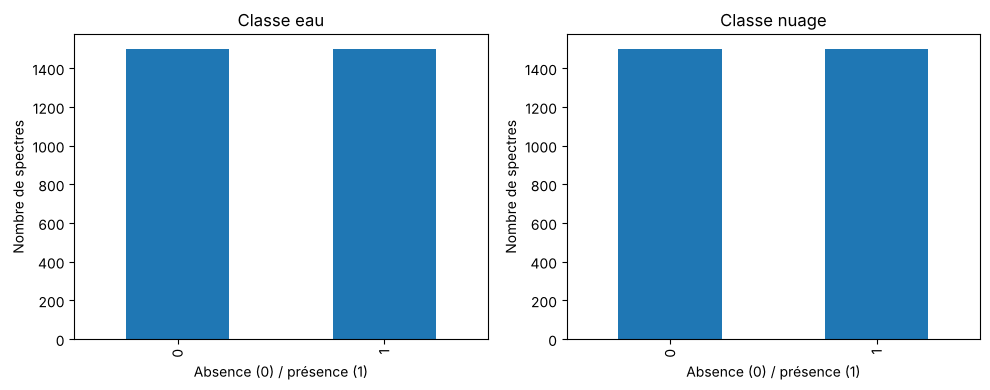

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["eau", "nuage"]):
    targets_train[col].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(f"Classe {col}")
    ax.set_xlabel("Absence (0) / présence (1)")
    ax.set_ylabel("Nombre de spectres")
plt.tight_layout()
plt.show()

Il y a à peu près autant de spectres avec et sans eau, et de même pour les nuages.

## Variables auxiliaires

On ramène les masses et rayons aux unités de Jupiter (planète) et du Soleil (étoile), puis on calcule quelques grandeurs physiques utiles.

In [9]:
RJUP = 69911000
MJUP = 1.898e27
RSOL = 696340000
MSOL = 1.9891e30

Le rayon théorique de la planète se déduit de sa masse et de sa gravité de surface : $$R_p = \sqrt{\frac{G \, M_p}{g}}$$ où $G$ est la constante gravitationnelle et $g$ la gravité de surface, fixée ici à 20 m/s².

In [10]:
def create_aux_features(auxiliary_df):
    aux = auxiliary_df.copy()

    aux["planet_surface_gravity"] = 20.0
    aux["th_radius"] = np.sqrt(aux["planet_mass_kg"] * 6.67e-11 / aux["planet_surface_gravity"]) / RJUP
    aux["star_radius"] = aux["star_radius_m"] / RSOL
    aux["planet_mass"] = aux["planet_mass_kg"] / MJUP
    aux["star_mass"] = aux["star_mass_kg"] / MSOL

    aux["planet_eq_temp"] = aux["star_temperature"] * np.sqrt(aux["star_radius"] * RSOL / (2.0 * aux["semi_major_axis_m"]))
    aux["surface_gravity_eff"] = aux["planet_mass"] / (aux["th_radius"]**2 + 1e-10)
    aux["insolation"] = (aux["star_radius"]**2 * aux["star_temperature"]**4) / (aux["semi_major_axis_m"]**2 + 1e-10)
    aux["mass_radius_ratio"] = aux["planet_mass"] / (aux["th_radius"]**3 + 1e-10)
    aux["scale_height"] = aux["planet_eq_temp"] / (aux["surface_gravity_eff"] + 1e-10)

    useful_cols = [
        "star_radius", "star_temperature", "planet_mass",
        "semi_major_axis_m", "star_mass", "th_radius",
        "planet_eq_temp", "surface_gravity_eff", "insolation",
        "mass_radius_ratio", "scale_height"
    ]

    return aux[useful_cols].values

## Variables tirées du spectre

En plus des 52 valeurs du spectre, on calcule des statistiques sur chaque spectre : moyenne, dispersion, asymétrie, aplatissement, écart entre les bandes FGS et AIRS, profondeur dans la bande de l'eau (1,1 à 1,6 µm), rapport signal/bruit, pente et courbure, entropie, autocorrélation et nombre de pics.

In [11]:
def create_ultra_spectral_features(spectra):
    spectra_features = []
    for spectrum in spectra:
        wavelengths = spectrum[:, 0]
        transit_depths = spectrum[:, 1]
        errors = spectrum[:, 2]

        mean_depth = np.mean(transit_depths)
        std_depth = np.std(transit_depths) + 1e-10

        gradient = np.gradient(transit_depths)
        max_gradient = np.max(np.abs(gradient))

        snr = np.mean(transit_depths / (errors + 1e-10))

        skewness = np.mean((transit_depths - mean_depth)**3) / (std_depth**3)

        fgs_mask = wavelengths < 1.95
        airs_mask = wavelengths >= 1.95
        fgs_mean = np.mean(transit_depths[fgs_mask])
        airs_mean = np.mean(transit_depths[airs_mask])
        band_difference = airs_mean - fgs_mean

        amplitude = np.max(transit_depths) - np.min(transit_depths)

        water_band_mask = (wavelengths >= 1.1) & (wavelengths <= 1.6)
        if np.sum(water_band_mask) > 0:
            water_band_depth = np.mean(transit_depths[water_band_mask])
            water_band_std = np.std(transit_depths[water_band_mask]) + 1e-10
        else:
            water_band_depth = mean_depth
            water_band_std = std_depth

        try:
            slope, intercept = np.polyfit(wavelengths, transit_depths, 1)
            poly_coeffs = np.polyfit(wavelengths, transit_depths, 2)
            curvature = poly_coeffs[0]
        except Exception:
            slope = 0.0
            curvature = 0.0

        try:
            hist, _ = np.histogram(transit_depths, bins=20)
            hist = hist.astype(float)
            hist_norm = hist / (hist.sum() + 1e-10)
            mask = hist_norm > 0
            entropy = -np.sum(hist_norm[mask] * np.log(hist_norm[mask]))
        except Exception:
            entropy = 0.0

        try:
            ac = np.correlate(transit_depths - mean_depth,
                              transit_depths - mean_depth,
                              mode='same')
            center = len(ac) // 2
            if center + 1 < len(ac):
                autocorr_max = np.max(ac[center+1:]) / (ac[center] + 1e-10)
            else:
                autocorr_max = 0.0
        except Exception:
            autocorr_max = 0.0

        kurtosis_val = np.mean((transit_depths - mean_depth)**4) / (std_depth**4)

        try:
            prominence_threshold = std_depth * 0.5
            peaks, _ = find_peaks(transit_depths, prominence=prominence_threshold)
            n_peaks = len(peaks)
        except Exception:
            n_peaks = 0

        spectra_features.append([
            mean_depth, std_depth, max_gradient, snr,
            skewness, band_difference, amplitude, fgs_mean, airs_mean,
            water_band_depth, water_band_std, slope, curvature,
            entropy, autocorr_max, kurtosis_val, n_peaks
        ])
    return np.array(spectra_features)

Les spectres sont normalisés un par un (médiane et écart absolu médian), pour retirer l'effet de la taille de la planète sur le niveau moyen.

In [12]:
def advanced_normalization(spectra_1d):
    normalized = []
    for spec in spectra_1d:
        median_val = np.median(spec)
        mad = np.median(np.abs(spec - median_val)) + 1e-10
        normalized.append((spec - median_val) / mad)
    return np.array(normalized)

In [13]:
spectra_depth_train = spectra_train[:, :, 1]
spectra_depth_test = spectra_test[:, :, 1]

In [14]:
spectra_features_train = create_ultra_spectral_features(spectra_train)
aux_features_train = create_aux_features(aux_train)
spectra_norm_train = advanced_normalization(spectra_depth_train)

X_train_all = np.concatenate(
    [spectra_norm_train, spectra_features_train, aux_features_train],
    axis=1
)
Y_eau = targets_train["eau"].values
Y_nuage = targets_train["nuage"].values

spectra_features_test = create_ultra_spectral_features(spectra_test)
aux_features_test = create_aux_features(aux_test)
spectra_norm_test = advanced_normalization(spectra_depth_test)

X_test_all = np.concatenate(
    [spectra_norm_test, spectra_features_test, aux_features_test],
    axis=1
)

print(f"X_train_all shape: {X_train_all.shape}")
print(f"X_test_all  shape: {X_test_all.shape}")

X_train_all shape: (3000, 80)
X_test_all  shape: (1032, 80)


In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_all)
X_test_scaled = scaler.transform(X_test_all)

## Modèles

Deux modèles de boosting, GradientBoosting (scikit-learn) et LightGBM, entraînés séparément pour l'eau et pour les nuages. Leurs probabilités sont moyennées.

In [16]:
# GradientBoosting
gb_params_eau = dict(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_samples_split=30,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
)
gb_params_nuage = dict(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    min_samples_split=30,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
)

# LightGBM 
lgb_params = dict(
    objective="binary",
    learning_rate=0.05,
    n_estimators=1000,
    num_leaves=63,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=0.0,
    random_state=42,
    verbose=-1
)

Validation croisée en 5 plis, stratifiée sur la combinaison eau/nuage. Les prédictions hors pli (OOF) servent à évaluer l'ensemble et à choisir les seuils ; les prédictions sur le test sont moyennées sur les 5 plis.

In [17]:
combined_label = Y_eau.astype(str) + "_" + Y_nuage.astype(str)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# OOF probabilities
oof_gb_eau = np.zeros(len(X_train_scaled))
oof_gb_nuage = np.zeros(len(X_train_scaled))
oof_lgb_eau = np.zeros(len(X_train_scaled))
oof_lgb_nuage = np.zeros(len(X_train_scaled))

# Test probabilities (fold-averaged)
test_gb_eau_folds = []
test_gb_nuage_folds = []
test_lgb_eau_folds = []
test_lgb_nuage_folds = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train_scaled, combined_label)):
    X_tr, X_val = X_train_scaled[tr_idx], X_train_scaled[val_idx]
    y_tr_eau, y_val_eau = Y_eau[tr_idx], Y_eau[val_idx]
    y_tr_nuage, y_val_nuage = Y_nuage[tr_idx], Y_nuage[val_idx]

    # ----- GradientBoosting -----
    gb_eau = GradientBoostingClassifier(**gb_params_eau)
    gb_eau.fit(X_tr, y_tr_eau)
    proba_val_gb_eau = gb_eau.predict_proba(X_val)[:, 1]
    proba_test_gb_eau = gb_eau.predict_proba(X_test_scaled)[:, 1]
    oof_gb_eau[val_idx] = proba_val_gb_eau
    test_gb_eau_folds.append(proba_test_gb_eau)

    gb_nuage = GradientBoostingClassifier(**gb_params_nuage)
    gb_nuage.fit(X_tr, y_tr_nuage)
    proba_val_gb_nuage = gb_nuage.predict_proba(X_val)[:, 1]
    proba_test_gb_nuage = gb_nuage.predict_proba(X_test_scaled)[:, 1]
    oof_gb_nuage[val_idx] = proba_val_gb_nuage
    test_gb_nuage_folds.append(proba_test_gb_nuage)

    # ----- LightGBM -----
    lgb_eau = LGBMClassifier(**lgb_params)
    lgb_eau.fit(X_tr, y_tr_eau)
    proba_val_lgb_eau = lgb_eau.predict_proba(X_val)[:, 1]
    proba_test_lgb_eau = lgb_eau.predict_proba(X_test_scaled)[:, 1]
    oof_lgb_eau[val_idx] = proba_val_lgb_eau
    test_lgb_eau_folds.append(proba_test_lgb_eau)

    lgb_nuage = LGBMClassifier(**lgb_params)
    lgb_nuage.fit(X_tr, y_tr_nuage)
    proba_val_lgb_nuage = lgb_nuage.predict_proba(X_val)[:, 1]
    proba_test_lgb_nuage = lgb_nuage.predict_proba(X_test_scaled)[:, 1]
    oof_lgb_nuage[val_idx] = proba_val_lgb_nuage
    test_lgb_nuage_folds.append(proba_test_lgb_nuage)

    # accuracy de chaque modèle au seuil 0.5
    acc_gb_eau = accuracy_score(y_val_eau, (proba_val_gb_eau >= 0.5).astype(int))
    acc_lgb_eau = accuracy_score(y_val_eau, (proba_val_lgb_eau >= 0.5).astype(int))
    acc_gb_nuage = accuracy_score(y_val_nuage, (proba_val_gb_nuage >= 0.5).astype(int))
    acc_lgb_nuage = accuracy_score(y_val_nuage, (proba_val_lgb_nuage >= 0.5).astype(int))
    print(f"Fold {fold+1} - Acc eau   GB/LGBM (0.5) : {acc_gb_eau:.4f} / {acc_lgb_eau:.4f}")
    print(f"Fold {fold+1} - Acc nuage GB/LGBM (0.5) : {acc_gb_nuage:.4f} / {acc_lgb_nuage:.4f}")

Fold 1 - Acc eau   GB/LGBM (0.5) : 0.9733 / 0.9700
Fold 1 - Acc nuage GB/LGBM (0.5) : 0.9633 / 0.9667


Fold 2 - Acc eau   GB/LGBM (0.5) : 0.9867 / 0.9833
Fold 2 - Acc nuage GB/LGBM (0.5) : 0.9767 / 0.9833


Fold 3 - Acc eau   GB/LGBM (0.5) : 0.9783 / 0.9850
Fold 3 - Acc nuage GB/LGBM (0.5) : 0.9767 / 0.9733


Fold 4 - Acc eau   GB/LGBM (0.5) : 0.9817 / 0.9800
Fold 4 - Acc nuage GB/LGBM (0.5) : 0.9600 / 0.9733


Fold 5 - Acc eau   GB/LGBM (0.5) : 0.9767 / 0.9717
Fold 5 - Acc nuage GB/LGBM (0.5) : 0.9767 / 0.9700


Le seuil de décision de chaque cible est choisi sur les prédictions hors pli, entre 0,3 et 0,7.

In [18]:
def find_best_threshold(y_true, y_proba):
    best_thr = 0.5
    best_acc = 0.0
    for thr in np.linspace(0.3, 0.7, 41):
        y_pred = (y_proba >= thr).astype(int)
        acc = accuracy_score(y_true, y_pred)
        if acc > best_acc:
            best_acc = acc
            best_thr = thr
    return best_thr, best_acc

In [19]:
# Moyenne simple des deux modèles
oof_ens_eau = 0.5 * oof_gb_eau + 0.5 * oof_lgb_eau
oof_ens_nuage = 0.5 * oof_gb_nuage + 0.5 * oof_lgb_nuage

best_thr_eau, best_acc_eau = find_best_threshold(Y_eau, oof_ens_eau)
best_thr_nuage, best_acc_nuage = find_best_threshold(Y_nuage, oof_ens_nuage)

print("\nRésultats OOF ensemble GB+LGBM :")
print(f"Eau   - best thr = {best_thr_eau:.3f} | acc = {best_acc_eau:.4f}")
print(f"Nuage - best thr = {best_thr_nuage:.3f} | acc = {best_acc_nuage:.4f}")
print(f"Accuracy moyenne OOF ensemble = {(best_acc_eau + best_acc_nuage)/2:.4f}")


Résultats OOF ensemble GB+LGBM :
Eau   - best thr = 0.370 | acc = 0.9813
Nuage - best thr = 0.470 | acc = 0.9747
Accuracy moyenne OOF ensemble = 0.9780


## Prédictions et soumission

In [20]:
test_gb_eau = np.mean(test_gb_eau_folds, axis=0)
test_gb_nuage = np.mean(test_gb_nuage_folds, axis=0)
test_lgb_eau = np.mean(test_lgb_eau_folds, axis=0)
test_lgb_nuage = np.mean(test_lgb_nuage_folds, axis=0)

test_ens_eau = 0.5 * test_gb_eau + 0.5 * test_lgb_eau
test_ens_nuage = 0.5 * test_gb_nuage + 0.5 * test_lgb_nuage

pred_eau_test = (test_ens_eau >= best_thr_eau).astype(int)
pred_nuage_test = (test_ens_nuage >= best_thr_nuage).astype(int)

print(f"\nDistribution eau (classe 1)   : {pred_eau_test.mean()*100:.1f}%")
print(f"Distribution nuage (classe 1) : {pred_nuage_test.mean()*100:.1f}%")


Distribution eau (classe 1)   : 48.8%
Distribution nuage (classe 1) : 52.5%


In [21]:
submission = pd.DataFrame({
    "id": np.arange(len(pred_eau_test)),
    "eau": pred_eau_test,
    "nuage": pred_nuage_test,
})
submission.to_csv("../submission.csv", index=False)